# Detección de fraude en tarjetas de crédito

**Componentes del grupo:** Javier Chulvi Bernad · Hugo Vinuesa Busson · Higinio Paterna Ortiz

**Objetivo:** construir un sistema de detección de fraude con el dataset etiquetado de construcción que maximice el
**AUPR** (área bajo la curva Precision-Recall, `average_precision_score`) en producción, y entregar un CSV con un score
por transacción de producción (mayor score = mayor probabilidad de fraude).

**Resumen del resultado**

| | AUPR (CV 5×3) |
|---|---|
| Línea base del notebook de partida (GMM sobre transacciones normales) | 0,636 |
| Mejor modelo individual (LightGBM) | 0,849 |
| **Modelo final: ensemble LightGBM + Extra Trees (media de rankings)** | **0,855** |

Se han comparado 15 algoritmos (5 no supervisados de detección de anomalías y 10 supervisados) con el mismo protocolo
de validación. Al final del notebook hay una reflexión sobre los resultados.

In [1]:
COLAB = False          # True para descargar los datos como en el notebook de partida
RUN_BENCHMARK = False  # True para re-ejecutar la comparación completa de 15 modelos (~1 h con 2 CPUs)

import os, time, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import ks_2samp, rankdata
from sklearn.metrics import average_precision_score, roc_auc_score, precision_recall_curve
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, IsolationForest
from sklearn.neighbors import LocalOutlierFactor, KNeighborsClassifier
from sklearn.mixture import GaussianMixture
from sklearn.neural_network import MLPClassifier, MLPRegressor
from sklearn.svm import OneClassSVM
import lightgbm as lgb, xgboost as xgb, catboost as cb
warnings.filterwarnings("ignore")
pd.options.display.max_columns = None
SEED = 0

# 1. Carga de datos

In [2]:
if COLAB:
    aux = "'https://drive.usercontent.google.com/download?id=1IyihCpU_krumRnPBvMR0ytEfzv_Z2Jg3&export=download&confirm=t&uuid=9699f0e2-e760-49fc-b12e-49f140095280'"
    !wget $aux -O ./credit_card_construction.csv.zip
    !unzip -qq -o ./credit_card_construction.csv.zip
    aux = "'https://drive.usercontent.google.com/download?id=1N5xRbkchTR7FLskuIEmZPYHklsRVJy_q&export=download&confirm=t&uuid=9699f0e2-e760-49fc-b12e-49f140095280'"
    !wget $aux -O ./credit_card_production.csv.zip
    !unzip -qq -o ./credit_card_production.csv.zip

DATA = "data" if os.path.exists("data/credit_card_construction.csv") else "."
df_const = pd.read_csv(f"{DATA}/credit_card_construction.csv")
df_prod = pd.read_csv(f"{DATA}/credit_card_production.csv")
FEATS = [c for c in df_const.columns if c != "Class"]
print("Construcción:", df_const.shape, "| Producción:", df_prod.shape)
print("Fraudes en construcción:", int(df_const.Class.sum()), f"({100*df_const.Class.mean():.3f} %)")
print("Nulos construcción / producción (features):", df_const[FEATS].isna().sum().sum(), "/", df_prod[FEATS].isna().sum().sum())

Construcción: (170884, 22) | Producción: (113923, 22)
Fraudes en construcción: 295 (0.173 %)
Nulos construcción / producción (features): 0 / 0


# 2. Análisis exploratorio

Puntos que condicionan el diseño:

1. **Desbalanceo extremo**: 295 fraudes entre 170.884 transacciones (0,17 %). Por eso la métrica es AUPR y no
   accuracy ni ROC: el ROC puede ser alto aunque haya muchos falsos positivos en lo alto del ranking.
2. **Variables anonimizadas** `X1…X20` (tipo componentes PCA, ordenadas por varianza) más `Amount`, muy asimétrica.
3. **Duplicados**: hay filas idénticas. Si caen a la vez en train y validación, inflan la métrica.
4. **Deriva** entre construcción y producción: si la hubiera, la validación no sería representativa.

In [3]:
dup = df_const[df_const.duplicated(FEATS, keep=False)]
g = dup.groupby(FEATS).Class.mean()
print(f"Filas duplicadas: {df_const.duplicated(FEATS).sum()} | grupos: {len(g)} | grupos con etiqueta mixta: {((g>0)&(g<1)).sum()}")
ks = pd.Series({f: ks_2samp(df_const[f], df_prod[f]).statistic for f in FEATS})
print(f"Estadístico KS construcción vs producción: máximo {ks.max():.4f} ({ks.idxmax()}) -> sin deriva apreciable")
df_const.groupby("Class")[FEATS].mean().T.round(1).T

Filas duplicadas: 4167 | grupos: 2436 | grupos con etiqueta mixta: 0


Estadístico KS construcción vs producción: máximo 0.0050 (X8) -> sin deriva apreciable


,X1,X2,X3,X4,X5,X6,X7,X8,X9,X10,X11,X12,X13,X14,X15,X16,X17,X18,X19,X20,Amount
Class,,,,,,,,,,,,,,,,,,,,,
0,2.3,-1.3,2.8,-1.7,1.4,0.5,2.0,0.0,0.9,1.9,-1.1,2.4,-0.3,2.3,0.0,1.7,2.1,0.5,0.1,-0.1,132.0
1,-982.6,744.9,-1427.4,899.0,-653.3,-288.5,-1157.4,108.7,-506.6,-1148.7,786.5,-1260.1,-18.1,-1440.3,-6.0,-853.6,-1371.5,-459.8,145.0,76.7,179.3


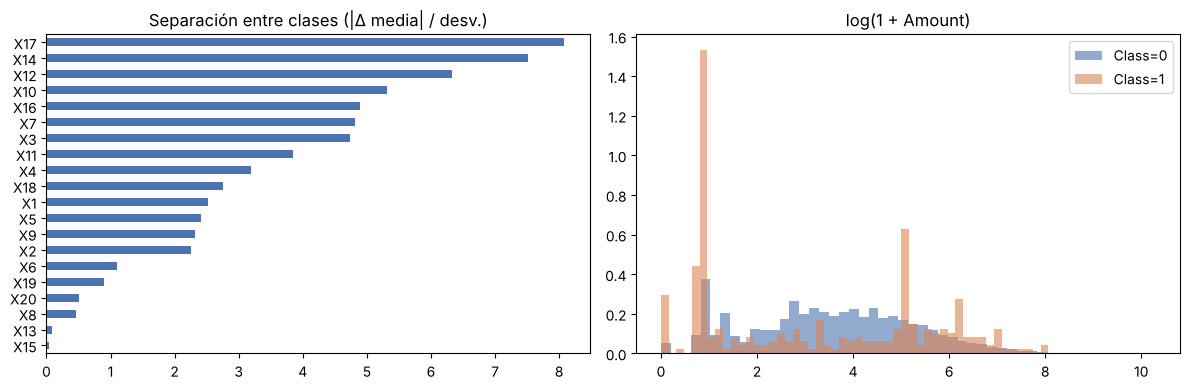

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sep = (df_const.groupby("Class")[FEATS].mean().diff().iloc[-1].abs() / df_const[FEATS].std()).drop("Amount").sort_values()
sep.plot.barh(ax=ax[0], color="#4C72B0"); ax[0].set_title("Separación entre clases (|Δ media| / desv.)")
for k, col in [(0, "#4C72B0"), (1, "#DD8452")]:
    ax[1].hist(np.log1p(df_const.loc[df_const.Class == k, "Amount"]), bins=50, density=True, alpha=.6, color=col, label=f"Class={k}")
ax[1].set_title("log(1 + Amount)"); ax[1].legend(); plt.tight_layout(); plt.show()

Casi todas las variables separan mucho los fraudes (medias de cientos de unidades frente a ~0 en las normales), salvo
`X13`, `X15` y `X20`. `Amount` separa poco y la transformamos con `log1p`. Los duplicados nunca tienen etiquetas
contradictorias, pero los agruparemos en la validación. No hay deriva: producción parece una partición aleatoria
del mismo origen, así que una validación cruzada bien hecha es un buen estimador del AUPR en producción.

# 3. Metodología de validación

- **Validación cruzada `StratifiedGroupKFold` de 5 particiones, repetida 3 veces** con semillas distintas (15 particiones).
  Estratificada para que cada partición tenga ~59 fraudes. Agrupada por fila (hash de las variables) para que
  los duplicados no se repartan entre train y validación.
- Con solo ~59 fraudes por partición el AUPR varía bastante (±0,04), por eso repetimos y comparamos medias.
  Las diferencias entre modelos se contrastan **por pares, partición a partición** (test de Wilcoxon).
- **No supervisados**: se ajustan solo con las transacciones normales del train (detección de novedades, igual que
  el GMM del notebook de partida). El score es "lo anómalo que es el punto".
- **Supervisados**: se entrenan con ambas clases y el score es la probabilidad de fraude.
- Las predicciones *out-of-fold* se guardan para evaluar ensembles sin reentrenar.

In [5]:
X = df_const[FEATS].copy(); X["Amount"] = np.log1p(X["Amount"]); X = X.values.astype(np.float32)
y = df_const["Class"].values
groups = pd.util.hash_pandas_object(df_const[FEATS], index=False).values
REPEATS, K = 3, 5
FOLDS = [(r, tr, va) for r in range(REPEATS)
         for tr, va in StratifiedGroupKFold(K, shuffle=True, random_state=r).split(X, y, groups)]

# 4. Algoritmos comparados

In [6]:
def unsup(score_fn):
    def fit_pred(Xtr, ytr, Xva):
        sc = StandardScaler().fit(Xtr[ytr == 0])
        return score_fn(sc.transform(Xtr[ytr == 0]), sc.transform(Xva))
    return fit_pred

def sup(make, scale=False):
    def fit_pred(Xtr, ytr, Xva):
        m = make_pipeline(StandardScaler(), make()) if scale else make()
        return m.fit(Xtr, ytr).predict_proba(Xva)[:, 1]
    return fit_pred

def _sub(A, n): return A[np.random.RandomState(SEED).choice(len(A), min(n, len(A)), replace=False)]
spw = (y == 0).sum() / (y == 1).sum()

MODELS = {
    # No supervisados (detección de anomalías)
    "GMM (notebook)":   unsup(lambda A, B: -GaussianMixture(n_components=5, random_state=SEED).fit(A).score_samples(B)),
    "Isolation Forest": unsup(lambda A, B: -IsolationForest(n_estimators=300, random_state=SEED, n_jobs=-1).fit(A).score_samples(B)),
    "LOF":              unsup(lambda A, B: -LocalOutlierFactor(n_neighbors=35, novelty=True, n_jobs=-1).fit(_sub(A, 30000)).score_samples(B)),
    "One-Class SVM":    unsup(lambda A, B: -OneClassSVM(nu=0.01, gamma="scale").fit(_sub(A, 10000)).score_samples(B)),
    "Autoencoder":      unsup(lambda A, B: ((MLPRegressor(hidden_layer_sizes=(16, 8, 16), max_iter=40, early_stopping=True,
                                              random_state=SEED).fit(A, A).predict(B) - B) ** 2).sum(1)),
    # Supervisados
    "Regresión logística":       sup(lambda: LogisticRegression(C=0.1, max_iter=2000), scale=True),
    "Reg. logística balanceada": sup(lambda: LogisticRegression(C=0.1, max_iter=2000, class_weight="balanced"), scale=True),
    "kNN (k=15)":    sup(lambda: KNeighborsClassifier(n_neighbors=15, weights="distance", n_jobs=-1), scale=True),
    "MLP":           sup(lambda: MLPClassifier(hidden_layer_sizes=(64, 32), alpha=1e-3, max_iter=200, early_stopping=True, random_state=SEED), scale=True),
    "Random Forest": sup(lambda: RandomForestClassifier(n_estimators=500, max_features="sqrt", n_jobs=-1, random_state=SEED)),
    "Extra Trees":   sup(lambda: ExtraTreesClassifier(n_estimators=500, n_jobs=-1, random_state=SEED)),
    "XGBoost":       sup(lambda: xgb.XGBClassifier(n_estimators=600, learning_rate=0.03, max_depth=5, subsample=0.8, colsample_bytree=0.7,
                                                    tree_method="hist", n_jobs=-1, random_state=SEED)),
    "XGBoost ponderado": sup(lambda: xgb.XGBClassifier(n_estimators=600, learning_rate=0.03, max_depth=5, subsample=0.8, colsample_bytree=0.7,
                                                    scale_pos_weight=np.sqrt(spw), tree_method="hist", n_jobs=-1, random_state=SEED)),
    "LightGBM":      sup(lambda: lgb.LGBMClassifier(n_estimators=600, learning_rate=0.02, num_leaves=15, min_child_samples=20, subsample=0.8,
                                                     subsample_freq=1, colsample_bytree=0.7, reg_lambda=1.0, n_jobs=-1, random_state=SEED, verbose=-1)),
    "CatBoost":      sup(lambda: cb.CatBoostClassifier(iterations=1000, learning_rate=0.05, depth=6, verbose=0, random_seed=SEED)),
}
TIPO = {k: ("No supervisado" if i < 5 else "Supervisado") for i, k in enumerate(MODELS)}

La celda siguiente ejecuta la comparación completa si `RUN_BENCHMARK = True` (tarda ~1 hora con 2 CPUs). Por defecto
carga los resultados ya obtenidos con exactamente este código, para que el notebook se pueda ejecutar en minutos.

In [7]:
if RUN_BENCHMARK:
    OOF, rows = {}, []
    for name, fit_pred in MODELS.items():
        t = time.time(); oof = np.zeros((REPEATS, len(y)))
        for r, tr, va in FOLDS:
            oof[r, va] = fit_pred(X[tr], y[tr], X[va])
        aps = [average_precision_score(y[va], oof[r, va]) for r, _, va in FOLDS]
        OOF[name] = oof
        rows.append([name, np.mean(aps), np.std(aps), np.mean([roc_auc_score(y, oof[r]) for r in range(REPEATS)]), round(time.time() - t)])
        print(f"{name:28s} AUPR {np.mean(aps):.4f} ± {np.std(aps):.4f}")
    res = pd.DataFrame(rows, columns=["modelo", "AUPR media", "AUPR desv.", "ROC AUC", "segundos"])
else:
    RES = {"Autoencoder": [0.6241, 0.088, 0.9372, 230], "Regresión logística": [0.761, 0.0387, 0.9758, 84],
           "Reg. logística balanceada": [0.7435, 0.0437, 0.9706, 89], "LightGBM": [0.8487, 0.0433, 0.98, 156],
           "XGBoost": [0.8407, 0.0466, 0.98, 145], "XGBoost ponderado": [0.8474, 0.0429, 0.9805, 138],
           "CatBoost": [0.8443, 0.0462, 0.9741, 306], "Random Forest": [0.8342, 0.0402, 0.9589, 1343],
           "Extra Trees": [0.8471, 0.0393, 0.9618, 367], "MLP": [0.7862, 0.0515, 0.9556, 154],
           "kNN (k=15)": [0.8045, 0.0471, 0.9285, 197], "LOF": [0.6596, 0.0552, 0.9625, 138],
           "One-Class SVM": [0.427, 0.086, 0.9548, 95], "GMM (notebook)": [0.6363, 0.0452, 0.9471, 148],
           "Isolation Forest": [0.2302, 0.0421, 0.961, 100]}
    res = pd.DataFrame([[k, *v] for k, v in RES.items()], columns=["modelo", "AUPR media", "AUPR desv.", "ROC AUC", "segundos"])
res["tipo"] = res.modelo.map(TIPO)
res = res.sort_values("AUPR media", ascending=False).reset_index(drop=True)
res.round(4)

,modelo,AUPR media,AUPR desv.,ROC AUC,segundos,tipo
0,LightGBM,0.8487,0.0433,0.9800,156,Supervisado
1,XGBoost ponderado,0.8474,0.0429,0.9805,138,Supervisado
2,Extra Trees,0.8471,0.0393,0.9618,367,Supervisado
3,CatBoost,0.8443,0.0462,0.9741,306,Supervisado
4,XGBoost,0.8407,0.0466,0.9800,145,Supervisado
5,Random Forest,0.8342,0.0402,0.9589,1343,Supervisado
6,kNN (k=15),0.8045,0.0471,0.9285,197,Supervisado
7,MLP,0.7862,0.0515,0.9556,154,Supervisado
8,Regresión logística,0.7610,0.0387,0.9758,84,Supervisado
9,Reg. logística balanceada,0.7435,0.0437,0.9706,89,Supervisado


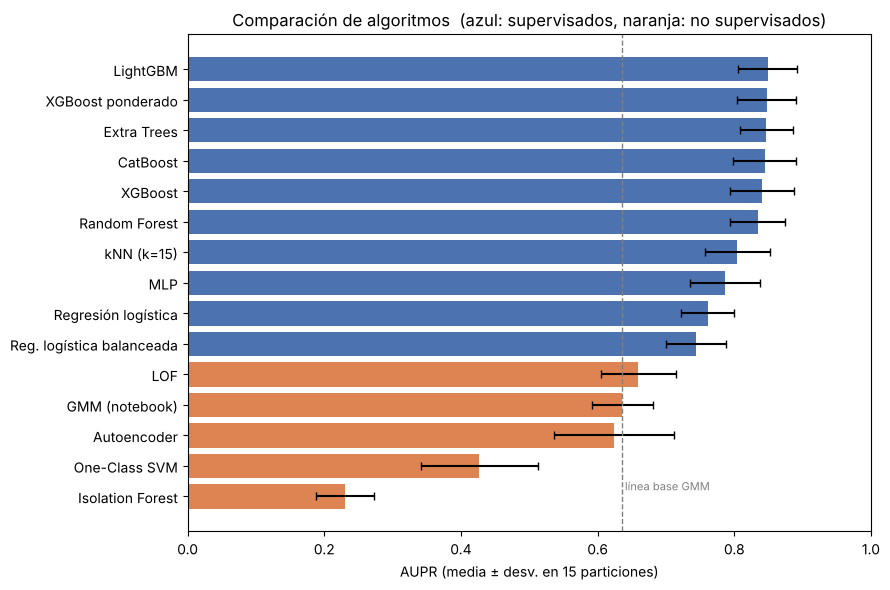

In [8]:
fig, ax = plt.subplots(figsize=(9, 6))
r = res.iloc[::-1]
ax.barh(r.modelo, r["AUPR media"], xerr=r["AUPR desv."], capsize=3,
        color=["#DD8452" if t == "No supervisado" else "#4C72B0" for t in r.tipo])
ax.axvline(0.6363, ls="--", c="grey", lw=1); ax.text(0.64, 0.2, "línea base GMM", color="grey", fontsize=8)
ax.set_xlabel("AUPR (media ± desv. en 15 particiones)"); ax.set_xlim(0, 1)
ax.set_title("Comparación de algoritmos  (azul: supervisados, naranja: no supervisados)")
plt.tight_layout(); plt.show()

**Lectura de la comparación**

- **Supervisado frente a no supervisado.** Todos los supervisados superan al mejor no supervisado (LOF, 0,660). Disponer de
  etiquetas permite aprender cómo es el fraude, no solo qué es raro: muchas transacciones legítimas también son raras
  (importes altos, combinaciones poco frecuentes) y los detectores de anomalías las ponen arriba del ranking. Eso se ve en
  Isolation Forest: ROC de 0,96 pero AUPR de solo 0,23.
- **Modelos de árboles.** LightGBM, XGBoost, CatBoost y Extra Trees están empatados en torno a 0,84–0,85: sus diferencias
  son mucho menores que la desviación entre particiones. Random Forest queda algo por detrás y es el más lento.
- **Repesar clases** (`class_weight`, `scale_pos_weight`) no mejora el AUPR de forma clara. El AUPR solo depende del
  orden de los scores y el repesado sobre todo descalibra las probabilidades.

# 5. Ensemble

Los modelos de boosting (secuenciales, reducen sesgo) y Extra Trees (bagging con cortes aleatorios, reduce varianza)
cometen errores distintos, así que combinarlos debería ayudar. Como sus scores están en escalas distintas, se combinan
por **media de rankings**. Con las predicciones out-of-fold se evaluaron todas las combinaciones de 2 a 4 modelos
entre los 10 mejores:

| Combinación | AUPR |
|---|---|
| LightGBM + CatBoost + Extra Trees | 0,8556 ± 0,044 |
| **LightGBM + Extra Trees** | **0,8553 ± 0,042** |
| LightGBM + XGBoost pond. + CatBoost + Extra Trees | 0,8546 ± 0,045 |
| LightGBM (solo) | 0,8487 ± 0,043 |

Contraste por pares frente a LightGBM solo: **LightGBM + Extra Trees mejora en 14 de 15 particiones** (+0,0066 de media,
Wilcoxon p = 0,001). Añadir CatBoost solo suma +0,0003, así que elegimos la combinación de **dos modelos** (más simple
y rápida). Al elegir entre muchas combinaciones hay algo de sesgo de selección, pero la mejora es consistente partición a
partición y tiene sentido metodológico. Combinar con modelos no supervisados (GMM, LOF) no aportó en ninguna combinación.

# 6. Comprobación en una partición de validación

Para ver las curvas Precision-Recall se reentrena en la primera partición (80 % / 20 %) la línea base del notebook,
los dos componentes y el ensemble final.

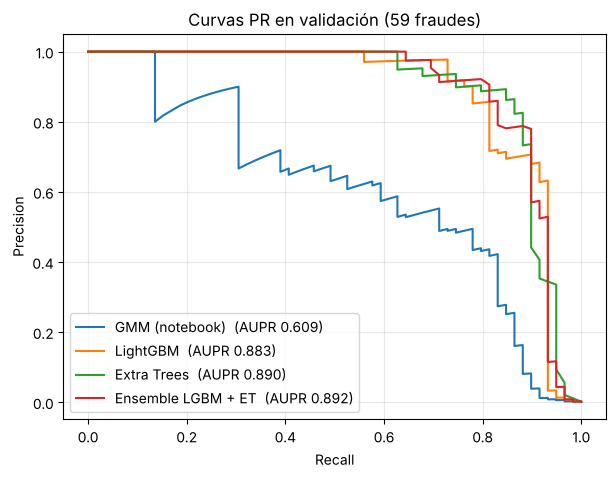

In [9]:
_, tr, va = FOLDS[0]
make_lgb = lambda: lgb.LGBMClassifier(n_estimators=600, learning_rate=0.02, num_leaves=15, min_child_samples=20, subsample=0.8,
                                      subsample_freq=1, colsample_bytree=0.7, reg_lambda=1.0, n_jobs=-1, random_state=SEED, verbose=-1)
make_et = lambda: ExtraTreesClassifier(n_estimators=500, n_jobs=-1, random_state=SEED)
rank = lambda s: rankdata(s) / len(s)

s = {"GMM (notebook)": MODELS["GMM (notebook)"](X[tr], y[tr], X[va]),
     "LightGBM": make_lgb().fit(X[tr], y[tr]).predict_proba(X[va])[:, 1],
     "Extra Trees": make_et().fit(X[tr], y[tr]).predict_proba(X[va])[:, 1]}
s["Ensemble LGBM + ET"] = (rank(s["LightGBM"]) + rank(s["Extra Trees"])) / 2

plt.figure(figsize=(7, 5))
for k, v in s.items():
    p, r_, _ = precision_recall_curve(y[va], v)
    plt.plot(r_, p, label=f"{k}  (AUPR {average_precision_score(y[va], v):.3f})")
plt.xlabel("Recall"); plt.ylabel("Precision"); plt.title(f"Curvas PR en validación ({y[va].sum()} fraudes)")
plt.legend(); plt.grid(alpha=.3); plt.show()

In [10]:
# ¿Qué supone en la práctica? Revisando las N transacciones con mayor score de la partición de validación:
e = s["Ensemble LGBM + ET"]; order = np.argsort(-e); yv = y[va][order]
pd.DataFrame([[n, yv[:n].sum(), y[va].sum(), yv[:n].mean(), yv[:n].sum() / y[va].sum()] for n in [25, 50, 75, 100, 200]],
             columns=["revisadas", "fraudes detectados", "fraudes totales", "precisión", "recall"]).round(3)

,revisadas,fraudes detectados,fraudes totales,precisión,recall
0,25,25,59,1.000,0.424
1,50,46,59,0.920,0.780
2,75,53,59,0.707,0.898
3,100,54,59,0.540,0.915
4,200,55,59,0.275,0.932


# 7. Modelo final y scores de producción

Se reentrenan LightGBM y Extra Trees con **todo** el dataset de construcción y se puntúa producción con la media de
rankings (score en (0, 1]; a mayor score, más probabilidad de fraude).

In [11]:
Xp = df_prod[FEATS].copy(); Xp["Amount"] = np.log1p(Xp["Amount"]); Xp = Xp.values.astype(np.float32)
p_lgb = make_lgb().fit(X, y).predict_proba(Xp)[:, 1]
p_et = make_et().fit(X, y).predict_proba(Xp)[:, 1]
score_prod = (rank(p_lgb) + rank(p_et)) / 2

out = pd.DataFrame({"score": score_prod})
out.to_csv("scores_produccion.csv", index=False)
print(out.shape, "-> scores_produccion.csv | filas producción:", len(df_prod))
print("Correlación de Spearman LightGBM vs Extra Trees en producción:", round(pd.Series(p_lgb).corr(pd.Series(p_et), method="spearman"), 3))
print("Transacciones con ambos modelos > 0.5:", int(((p_lgb > .5) & (p_et > .5)).sum()), "(en construcción hay un 0,17 % de fraude ≈", round(0.00173 * len(df_prod)), "esperados)")

(113923, 1) -> scores_produccion.csv | filas producción: 113923
Correlación de Spearman LightGBM vs Extra Trees en producción: 0.315
Transacciones con ambos modelos > 0.5: 146 (en construcción hay un 0,17 % de fraude ≈ 197 esperados)


# 8. Reflexión final

- **El salto grande lo da usar las etiquetas.** El enfoque del notebook de partida (modelar la distribución de las
  transacciones normales con un GMM) es razonable cuando no hay etiquetas, pero aquí hay 295 fraudes etiquetados y
  aprovecharlos sube el AUPR de 0,64 a 0,85. Los detectores de anomalías tienen ROC altos (0,94–0,96) y aun así un AUPR
  pobre: separan bien en conjunto, pero en lo alto del ranking mezclan muchas transacciones raras pero legítimas, que es
  justo lo que castiga el AUPR.
- **Entre los buenos modelos, el techo es parecido.** Los modelos de árboles empatan en ~0,85. Con ~59 fraudes por
  partición, la incertidumbre del AUPR (±0,04) es mayor que las diferencias entre ellos, así que hay que comparar con
  contrastes por pares y varias repeticiones, no con un único train/test.
- **El ensemble aporta poco pero de forma consistente** (+0,007, mejora en 14/15 particiones). Combinar boosting con un
  bagging aleatorizado como Extra Trees aprovecha errores poco correlacionados.
- **Cuidado con la validación.** Las filas duplicadas podrían inflar la métrica si caen a ambos lados del corte; por eso
  la validación está agrupada. No hay deriva entre construcción y producción, así que esperamos un AUPR en producción
  en torno a 0,85, con una variación del orden de ±0,04 por el bajo número de fraudes.
- **Qué probaríamos con más tiempo:** búsqueda de hiperparámetros (p. ej. Optuna) dentro de la validación cruzada,
  *stacking* con un metamodelo en lugar de la media de rankings, y técnicas de remuestreo (SMOTE, *undersampling*),
  aunque el repesado de clases ya mostró que con AUPR suelen aportar poco. En un sistema real habría que fijar además
  un umbral según la capacidad de revisión del equipo antifraude (ver la tabla de la sección 6).